# Pretraining a GPT Language Model

Pretrains a 162M parameter decoder-only GPT model from scratch using next-token causal prediction on unlabeled text. Uses approximately 3 million tokens from the TinyStories dataset, implements sliding-window data loading, computes cross-entropy loss, trains the model with AdamW, and evaluates both greedy and top-k sampling text generation.

## Table of Contents
1. Imports and Setup
2. GPT Architecture Configuration
3. Importing the GPT Model Architecture
4. Text Generation Utilities
5. Dataset Loading and Truncation
6. PyTorch Dataset and Sliding-Window DataLoader
7. Training and Validation Split
8. Device Configuration and Loss Calculation
9. Model Training Loop
10. Loss Visualization
11. Advanced Text Generation
12. Saving Model Weights and Checkpoints
13. Verifying Checkpoint Reloading


## 1. Imports and Setup

Imports the libraries required for tensor operations, neural networks, tokenization, and dataset handling.


In [1]:
import json 
import os 
import math

import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
import tiktoken

from importlib.metadata import version

## 2. GPT Architecture Configuration

Defines architecture hyperparameters for the 162M parameter model: vocabulary size 50,257, context length 256, embedding dimension 768, 12 layers, and 12 attention heads.


In [2]:
GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

## 3. Importing the GPT Model Architecture

Loads the `GPTModel` class and `generate_text_simple` function dynamically from the architecture notebook.


In [3]:
import json
import os

def import_from_ipynb(nb_path, *names):
    """Execute notebook code cells that define classes/functions/configs, skipping test runs."""
    candidates = [
        nb_path,
        os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', nb_path),
        os.path.abspath(f"src/buildinglargelanguagemodel/LLM/{nb_path}"),
        f"/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/LLM/{nb_path}"
    ]
    resolved_path = next((p for p in candidates if os.path.exists(p)), None)
    if not resolved_path:
        raise FileNotFoundError(f"Could not find {nb_path}.")

    with open(resolved_path, "r", encoding="utf-8") as f:
        nb_data = json.load(f)

    skip_signatures = [
        "logits = model(batch)",
        "start_context =",
        "layer_sizes =",
        "batch = torch.tensor",
        "out_ffn = ffn(",
        "out_att = att(",
        "out_block = block(",
        "ln_out = ln(",
        "y_gelu = gelu(x)",
        "total_params = sum("
    ]

    code_blocks = []
    for cell in nb_data.get("cells", []):
        if cell.get("cell_type") == "code":
            src = "".join(cell.get("source", []))
            if any(sig in src for sig in skip_signatures):
                continue
            code_blocks.append(src)

    exec_scope = {}
    exec("\n\n".join(code_blocks), exec_scope)
    return [exec_scope[name] for name in names]

GPTModel, generate_text_simple = import_from_ipynb("llm_architecture.ipynb", "GPTModel", "generate_text_simple")

Successfully imported CausalMultiHeadSelfAttention from: /home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb


Initializes the model with random weights to establish an untrained baseline.


In [4]:
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG)
model.eval()

print("Model initialized successfully!")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Model initialized successfully!
Total parameters: 162419712


## 4. Text Generation Utilities

Defines tokenization helper functions (`text_to_token_ids` and `token_ids_to_text`) and greedy autoregressive generation.


In [5]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)

        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [6]:
def text_to_token_ids(text, tokenizer):

    encoded = tokenizer.encode(text, allowed_special = {"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)

    return encoded_tensor 

In [7]:
start_context = "non of the above"

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = text_to_token_ids(start_context, tokenizer)
token_ids 

tensor([[13159,   286,   262,  2029]])

In [8]:
def token_ids_to_text(token_ids , tokenizer):

    flat = token_ids.squeeze(0)

    return tokenizer.decode(flat.tolist())

token_ids_to_text(token_ids, tokenizer)

'non of the above'

Generates text using the untrained model to inspect initial output quality before pretraining.


In [9]:
token_ids = generate_text_simple(

    model = model,
    idx = text_to_token_ids(start_context, tokenizer),
    max_new_tokens = 10,
    context_size = GPT_CONFIG["context_length"]
)

In [10]:
token_ids.squeeze_(0)

tensor([13159,   286,   262,  2029, 24075,  7901, 48218, 13772, 29924, 35075,
        39357, 17297, 13981, 10274])

In [11]:
token_ids_to_text(token_ids, tokenizer)

'non of the above Wisdom commitment Bridgewater blamed repo juicy698 Jin MLS Ban'

Computes cross-entropy loss between predicted logits and target tokens to evaluate initial prediction error.


In [12]:
# log_probs = torch.log(torch.cat((target_probas_1 , target_probas_2)))
# -1*torch.mean(log_probs)
# print(log_probs)

## 5. Dataset Loading and Truncation

Loads the TinyStories dataset and truncates it cleanly at an `<|endoftext|>` story boundary to approximately 3 million tokens.


In [13]:
# Load and truncate TinyStories dataset to ~3 Million tokens cleanly at story boundary
file_path = "/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/data/train.txt"

with open(file_path, "r", encoding="utf-8") as file:
    raw_text = file.read()

TARGET_TOKENS = 3_000_000
# Find clean story boundary (\n\n) near 3M tokens (~11.98 MB of text)
approx_chars = int(TARGET_TOKENS * 3.993)
cut_boundary = raw_text.find("\n\n", approx_chars)
content = raw_text[:cut_boundary] if cut_boundary != -1 else raw_text[:approx_chars]

print(f"Loaded truncated corpus: {len(content) / (1024**2):.2f} MB")
print(f"Preview (first 100 chars):\n{content[:100]}...")


Loaded truncated corpus: 11.42 MB
Preview (first 100 chars):
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with...


Displays total character and BPE token counts for the truncated corpus.


In [14]:
total_character = len(content)
total_token = len(tokenizer.encode(content))

print(f"Characters: {total_character:,}")
print(f"Tokens    : {total_token:,}")


Characters: 11,979,063
Tokens    : 3,000,308


## 6. PyTorch Dataset and Sliding-Window DataLoader

Implements `GPTDatasetV1` and a sliding-window data loader to extract overlapping input-target pairs for causal prediction.


In [15]:
import torch
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt,allowed_special={"<|endoftext|>"})            
            
        for i in range(0, len(token_ids) - max_length, stride):

            input_chunk = token_ids[i : i + max_length]

            target_chunk = token_ids[i + 1 : i + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [16]:
def create_dataloader_v1(txt, batch_size = 4, max_length = 256, stride = 128, shuffle = True, drop_last = True, num_workers = 0):

    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTDatasetV1(txt , tokenizer ,max_length, stride)

    dataloader = DataLoader(
        dataset,
        batch_size = batch_size,
        shuffle = shuffle,
        drop_last = drop_last,
        num_workers = num_workers,
    )

    return dataloader

## 7. Training and Validation Split

Splits the 3M-token corpus into a 90% training partition and a 10% validation partition.


In [17]:
train_ratio = 0.90
split_idx = int(train_ratio * len(content))
train_data = content[:split_idx]
val_data = content[split_idx:]

Initializes PyTorch DataLoaders for both training and validation splits with batch size 4.


In [18]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size = 2,
    max_length = GPT_CONFIG['context_length'],
    stride = GPT_CONFIG['context_length'],
    drop_last = True,
    shuffle = True,
    num_workers = 0
)


val_loader = create_dataloader_v1(
    val_data,
    batch_size = 2,
    max_length = GPT_CONFIG['context_length'],
    stride = GPT_CONFIG['context_length'],
    drop_last = False,
    shuffle = False,
    num_workers = 0
)

Inspects sample batches from each loader and verifies tensor dimensions.


In [19]:
print("Train data preview (first 3 batches):")
for i, (x, y) in enumerate(train_loader):
    if i >= 3:
        break
    print(f"Batch {i}: inputs {x.shape}, targets {y.shape}")


Train data preview (first 3 batches):
Batch 0: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 1: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 2: inputs torch.Size([2, 256]), targets torch.Size([2, 256])


In [20]:
print("Val data preview (first 3 batches):")
for i, (x, y) in enumerate(val_loader):
    if i >= 3:
        break
    print(f"Batch {i}: inputs {x.shape}, targets {y.shape}")


Val data preview (first 3 batches):
Batch 0: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 1: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 2: inputs torch.Size([2, 256]), targets torch.Size([2, 256])


In [ ]:
train_tokens = len(train_loader) * train_loader.batch_size * GPT_CONFIG["context_length"]
val_tokens = len(val_loader) * val_loader.batch_size * GPT_CONFIG["context_length"]

print(f"Train Tokens     : {train_tokens:,} ({len(train_loader):,} batches)")
print(f"Validation tokens: {val_tokens:,} ({len(val_loader):,} batches)")
print(f"Total tokens     : {train_tokens + val_tokens:,}")


Train Tokens     : 2,694,656 (5,263 batches)
Validation tokens: 305,664 (597 batches)
Total tokens     : 3,000,320


## 8. Device Configuration and Loss Calculation

Configures the compute device and defines cross-entropy loss calculation functions for individual batches and entire DataLoaders.


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device 

device(type='cuda')

In [23]:
def calc_loss_batch(input_batch, target_batch, model, device):

    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):

    total_loss = 0.

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
        
    return total_loss / num_batches

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using {device} device.")
model.to(device)

torch.manual_seed(123)
with torch.no_grad(): 
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=10)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=10)

print(f"Initial Training loss  : {train_loss:.3f}")
print(f"Initial Validation loss: {val_loss:.3f}")


Using cuda device.
Initial Training loss  : 10.937
Initial Validation loss: 10.939


## 9. Model Training Loop

Implements the autoregressive training loop (`train_model_simple`) with the AdamW optimizer, tracking loss across training steps.


In [ ]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1


    for epoch in range(num_epochs):
        model.train()  
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() 
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() 
            optimizer.step() 
            tokens_seen += input_batch.numel()
            global_step += 1

            
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

       
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " ")) 
    model.train()

Executes model pretraining and tracks training and validation loss values across iterations.


In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 1
train_losses, val_losses, tokens_seen = train_model_simple(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=num_epochs,
    eval_freq=100,
    eval_iter=5,
    start_context="Every effort moves you",
    tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.699, Val loss 9.894
Ep 1 (Step 000100): Train loss 4.830, Val loss 5.111
Ep 1 (Step 000200): Train loss 4.796, Val loss 4.610
Ep 1 (Step 000300): Train loss 4.426, Val loss 4.487
Ep 1 (Step 000400): Train loss 4.176, Val loss 4.313
Ep 1 (Step 000500): Train loss 4.181, Val loss 4.224
Ep 1 (Step 000600): Train loss 4.017, Val loss 4.135
Ep 1 (Step 000700): Train loss 4.090, Val loss 4.094
Ep 1 (Step 000800): Train loss 3.779, Val loss 4.031
Ep 1 (Step 000900): Train loss 3.859, Val loss 3.972
Ep 1 (Step 001000): Train loss 4.092, Val loss 3.959
Ep 1 (Step 001100): Train loss 3.846, Val loss 3.907
Ep 1 (Step 001200): Train loss 3.785, Val loss 3.879
Ep 1 (Step 001300): Train loss 4.006, Val loss 3.852
Ep 1 (Step 001400): Train loss 4.217, Val loss 3.837
Ep 1 (Step 001500): Train loss 3.732, Val loss 3.820
Ep 1 (Step 001600): Train loss 4.024, Val loss 3.833
Ep 1 (Step 001700): Train loss 3.823, Val loss 3.865
Ep 1 (Step 001800): Train loss 3.703, Val loss

## 10. Loss Visualization

Plots training and validation loss curves over epochs and total tokens seen to evaluate model convergence.


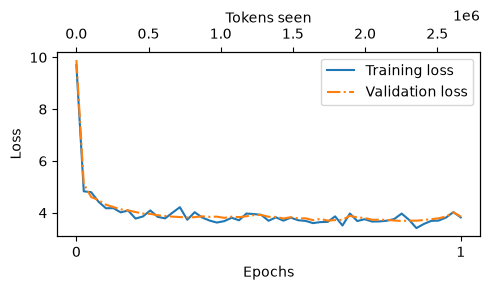

In [27]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  
    ax2 = ax1.twiny()  
    ax2.plot(tokens_seen, train_losses, alpha=0)  
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

## 11. Advanced Text Generation

Implements `generate` with temperature scaling, top-k filtering, and EOS stopping to produce coherent text completions.


In [ ]:
inference_device = torch.device("cuda")

model.to(inference_device)
model.eval()

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=25,
    context_size=GPT_CONFIG["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))


Output text:
 Every effort moves you can play.
The boy and said, "I'm you want to play with you, you can the box you want


In [ ]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

      
        if top_k is not None:
       
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

   
        if temperature > 0.0:
            logits = logits / temperature

            logits = logits - logits.max(dim=-1, keepdim=True).values            
            
            probs = torch.softmax(logits, dim=-1) 

            idx_next = torch.multinomial(probs, num_samples=1)  

        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  

        if idx_next == eos_id:  
            break

        idx = torch.cat((idx, idx_next), dim=1)

    return idx

Generates text completions using the pretrained model with temperature scaling and top-k sampling.


In [ ]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=15,
    context_size=GPT_CONFIG["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you ErrorARDIS� Lana Mock wholesalespot traditional historyWowliness landfall Germans arrange odor


## 12. Saving Model Weights and Checkpoints

Saves the trained model state dictionary (`model.pth`) to disk.


In [ ]:
torch.save(model.state_dict(), "model.pth")
print("Model weights saved successfully to model.pth!")


Model weights saved successfully to model.pth!


Reloads the saved model state dictionary into a new instance to confirm checkpoint validity.


In [ ]:
model = GPTModel(GPT_CONFIG)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    major, minor = map(int, torch.__version__.split(".")[:2])
    if (major, minor) >= (2, 9):
        device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

model.load_state_dict(torch.load("model.pth", map_location=device, weights_only=True))
model.eval();

Device: cuda


Saves both model weights and optimizer states in a combined checkpoint file (`model_and_optimizer.pth`).


In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)

## 13. Verifying Checkpoint Reloading

Loads and verifies the combined model and optimizer checkpoint from disk.


In [43]:
checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)

model = GPTModel(GPT_CONFIG)
model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();